# Tissue contexts relevant to 5-FU response

Two mechanisms of resistance to 5-fluorouracil (5-FU) have been described in colorectal cancer, acting at different steps. This notebook measures the closest readout of each in every patient, then shows how two multicellular programs of `MOFACell.ipynb` split patients into groups carrying one, both or neither.

| Published mechanism | Reference | Readout measured here |
|---|---|---|
| Macrophages in hypoxic tissue express dihydropyrimidine dehydrogenase, which breaks down 5-FU before it reaches the tumour cells | Malier et al. 2021, Gharzeddine et al. 2024 | CA9-high macrophages: the fraction of the macrophages of a core above the cohort's 75th percentile of macrophage CA9 |
| Cells that survive 5-FU build more mitochondria, and blocking complex I restores sensitivity. Oxidative phosphorylation signatures went with poor outcome after adjuvant 5-FU | Moss et al. 2026 | Mitochondrial markers in epithelial cells: the mean z-score across patients of ATP5A, CytC, CS, MCT1, GLS and CPT1A |

The first mechanism limits how much active drug reaches the epithelial cells. The second helps the cells that receive it survive. The readouts measure cells and proteins, not the mechanisms. Dihydropyrimidine dehydrogenase, metabolic flux and drug response are not measured, so the last section gives hypotheses rather than conclusions.

Macrophages are the CD68 and CD163 populations of the consensus annotation, the cells in which Malier et al. described the mechanism. CA9 is the hypoxia marker used throughout this project. The appendix checks that CA9 measured in a macrophage reflects the hypoxia of its region rather than signal from a neighbouring epithelial cell. Epithelial cells are the cells annotated `Cancer_cell`, PanCK-positive cells of the tumour cores. Each core is one patient, and the samples are resections taken mostly before treatment.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import anndata as ad
import muon as mu
from plotnine import *
from mizani.bounds import squish
from scanpy.plotting.palettes import default_20
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

data_dir = "../../data/"
output_dir = data_dir + "therapeutic/"
figure_dir = "../../figures/therapeutic/"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

# Decisions, set before computing any result
um_per_px = 400 / 1024          # 400 µm FOVs of 1024 pixels
epithelial_label = "Cancer_cell"
macrophage_types = ["CD68_Macrophage", "CD163_Macrophage"]
mitochondrial_markers = ["ATP5A", "CytC", "CS", "MCT1", "GLS", "CPT1A"]  # mitochondrial pathway of the metabolism notebooks
ca9_quantile = 0.75             # a cell is CA9-high above this quantile of CA9 within its own population
factor_split_quantile = 0.5     # each program is split at its median
min_abs_rho, fdr = 0.3, 0.05

def scale_fill_correlation(name="", limits=(-1, 1)):
    return scale_fill_gradient2(low="#FC8D62", mid="white", high="#6291FC", midpoint=0, limits=limits, oob=squish, name=name)
stage_colors = {"pT1": "#f2f0f7", "pT2": "#cbc9e2", "pT3": "#9e9ac9", "pT4": "#6a51a3"}

# Half violins with a white dot at the median, as in the lineage and metabolism notebooks
def half_violins(fill):
    return [geom_violin(aes(fill=fill), style="right", scale="width", width=1.25, size=0.3),
            stat_summary(fun_y=np.median, geom="point", color="white", size=1.5)]

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data
Factor scores of the tumour cores, in the order of the FOVs of the MuVI input, as checked in `sampling/FactorActivity.ipynb`. Healthy cores are left out. Cells, marker intensities and clinical annotations come from the cell table. pT and MSI are defined as in `MOFACell.ipynb`.

In [2]:
features = mu.read_h5mu(data_dir + "celltype_features_with_functional_markers.h5mu")
factor_order = [f"Factor {i}" for i in range(1, 11)]
scores = pd.read_csv(data_dir + "factor_scores.csv")
assert len(scores) == features.n_obs and (scores.Stage.values == features.obs.Stage.values).all()
scores.index = features.obs_names
patients = features.obs_names[features.obs.Stage != "Colon-no."]
scores = scores.loc[patients, factor_order]

marker_columns = mitochondrial_markers + ["CA9"]
cell_table = pd.read_csv(data_dir + "cell_table_with_types_stage.csv", low_memory=False,
                         usecols=["fov", "annotation_consensus", "centroid-0", "centroid-1"] + marker_columns
                                 + ["pT group", "MSI gesamt RED"])
cells = cell_table[cell_table.fov.isin(patients)].rename(
    columns={"annotation_consensus": "cell_type", "centroid-0": "x", "centroid-1": "y"}).reset_index(drop=True)
cells["epithelial"] = cells.cell_type == epithelial_label
cells["macrophage"] = cells.cell_type.isin(macrophage_types)

clinical_raw = cells.groupby("fov")[["pT group", "MSI gesamt RED"]].first().loc[patients]
clinical = pd.DataFrame({"pT": pd.Categorical(clinical_raw["pT group"], categories=list(stage_colors)),
                         "MSI": clinical_raw["MSI gesamt RED"].map({"stabil": "MSS", "instabil": "MSI"})}, index=patients)
print(len(patients), "patients,", cells.epithelial.sum(), "epithelial cells,", cells.macrophage.sum(), "macrophages,",
      int(cells.macrophage.groupby(cells.fov).sum().median()), "macrophages in the median core")

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


418 patients, 256750 epithelial cells, 17400 macrophages, 27 macrophages in the median core


## 1. The two readouts
A macrophage counts as CA9-high above the 75th percentile of CA9 among all macrophages of the cohort. The cutoff is taken within the macrophage population, because macrophages express much less CA9 than epithelial cells, so a cutoff built on epithelial cells would call almost none of them hypoxic. The readout is then the fraction of a core's macrophages that are CA9-high, which follows the published definition of a hypoxic macrophage population. A few cores hold no macrophage at all and have no value.

In [3]:
zscore = lambda s: (s - s.mean()) / s.std()
macrophages = cells[cells.macrophage]
epithelial_cells = cells[cells.epithelial]
macrophage_ca9_cutoff = macrophages.CA9.quantile(ca9_quantile)
epithelial_ca9_cutoff = epithelial_cells.CA9.quantile(ca9_quantile)
cells["ca9_high_epithelial"] = cells.epithelial & (cells.CA9 > epithelial_ca9_cutoff)

readouts = pd.DataFrame({
    "CA9-high macrophages": macrophages.CA9.gt(macrophage_ca9_cutoff).groupby(macrophages.fov).mean(),
    "Mitochondrial markers in epithelial cells":
        pd.concat([zscore(epithelial_cells.groupby("fov")[m].median()) for m in mitochondrial_markers], axis=1).mean(axis=1),
}).loc[patients]
percentiles = readouts.rank(pct=True)
print(f"CA9-high cutoff: {macrophage_ca9_cutoff:.3f} in macrophages, {epithelial_ca9_cutoff:.3f} in epithelial cells")
print(f"{readouts.iloc[:, 0].isna().sum()} patients have no macrophage and no value for the first readout")
print("Spearman rho between the two readouts across patients: %.2f"
      % spearmanr(readouts.iloc[:, 0], readouts.iloc[:, 1], nan_policy="omit")[0])
readouts.describe().round(3)

CA9-high cutoff: 0.158 in macrophages, 0.215 in epithelial cells
5 patients have no macrophage and no value for the first readout
Spearman rho between the two readouts across patients: 0.33


,CA9-high macrophages,Mitochondrial markers in epithelial cells
count,413.000,418.000
mean,0.210,-0.000
std,0.276,0.783
min,0.000,-1.733
25%,0.000,-0.508
50%,0.087,0.029
75%,0.308,0.553
max,1.000,2.272


## 2. Programs that follow the two readouts
Spearman correlation between each readout and each factor score across patients, with the Benjamini-Hochberg FDR across the matrix. Values are written where q < 0.05 and |rho| > 0.3. The mitochondrial markers are MuVI input features, so their correlations show which programs carry them rather than independent evidence. The fraction of CA9-high macrophages is not an input feature, since MuVI received the median CA9 of each cell type.

Several programs follow both readouts. The example needs a pair that tells them apart, and two columns do: Factor 3 follows the mitochondrial markers and ignores the CA9-high macrophages, while Factor 5 does the reverse. Both columns are outlined.

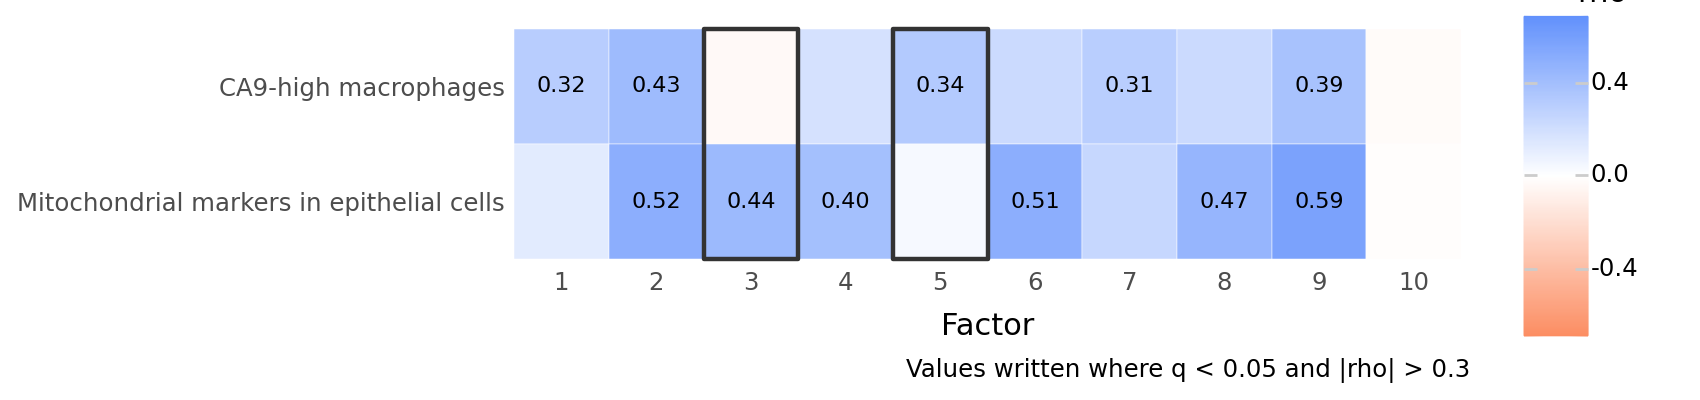

In [4]:
selected = ["Factor 3", "Factor 5"]
program_map = pd.DataFrame([{"readout": r, "factor": f,
                             **dict(zip(["rho", "p"], spearmanr(readouts[r], scores[f], nan_policy="omit")))}
                            for r in readouts for f in factor_order])
program_map["q"] = multipletests(program_map.p, method="fdr_bh")[1]
program_map["text"] = [f"{r:.2f}" if q < fdr and abs(r) > min_abs_rho else "" for r, q in zip(program_map.rho, program_map.q)]
program_map["readout"] = pd.Categorical(program_map.readout, categories=list(readouts)[::-1])
program_map["factor_label"] = pd.Categorical(program_map.factor.str.replace("Factor ", ""),
                                             categories=[str(i) for i in range(1, 11)])
outline = pd.DataFrame({"factor_label": pd.Categorical([f.replace("Factor ", "") for f in selected],
                                                       categories=program_map.factor_label.cat.categories),
                        "y": [1.5] * len(selected)})

gp = (ggplot(program_map, aes(x="factor_label", y="readout", fill="rho"))
      + geom_tile(color="white")
      + geom_text(aes(label="text"), size=8)
      + geom_tile(aes(x="factor_label", y="y"), data=outline, inherit_aes=False, width=1, height=2,
                  fill="none", color="#333333", size=0.9)
      + scale_fill_correlation("Spearman\nrho", limits=(-0.7, 0.7))
      + labs(x="Factor", y="", caption=f"Values written where q < {fdr} and |rho| > {min_abs_rho}")
      + theme_classic()
      + theme(figure_size=(8.5, 2), axis_line=element_blank(), axis_ticks=element_blank()))
gp.save(figure_dir + "readouts_by_program.pdf", verbose=False)
gp

The loadings explain why. Factor 3 weighs ATP5A and CS in every cell type and weighs CA9 negatively, so it is an oxidative phosphorylation axis. Factor 5 weighs CA9 in every cell type, 0.57 in macrophages, so it is a hypoxia axis.

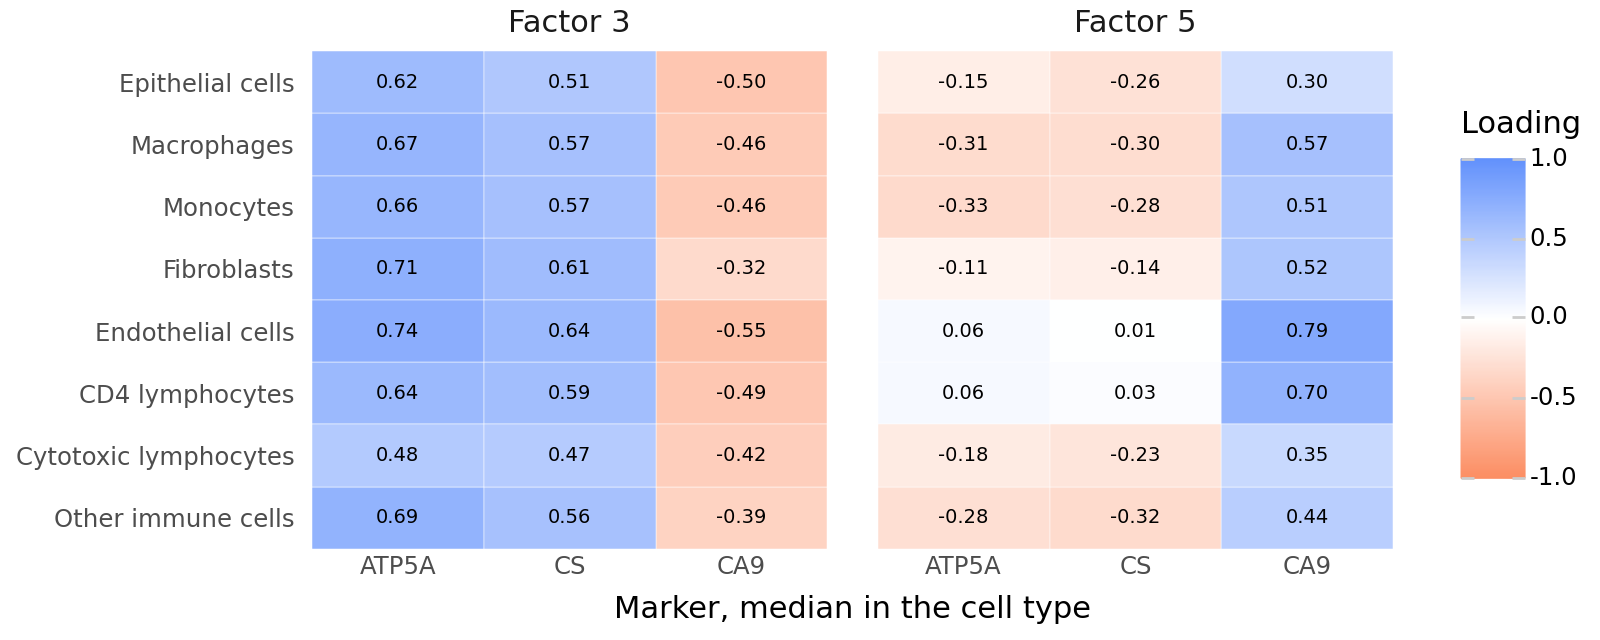

In [5]:
loadings = pd.read_csv(data_dir + "sampling/muvi_reference_loadings.csv")
view_names = {"Epithelial_cell": "Epithelial cells", "Macrophage": "Macrophages", "Monocyte": "Monocytes",
              "Fibroblast": "Fibroblasts", "Endothelial_cell": "Endothelial cells", "CD4_lymphocyte": "CD4 lymphocytes",
              "Cytotoxic_lymphocyte": "Cytotoxic lymphocytes", "Other_immune_cell": "Other immune cells"}
shown = loadings[loadings.feature.isin(["CA9", "ATP5A", "CS"])].copy()
shown["view"] = pd.Categorical(shown.view.map(view_names), categories=list(view_names.values())[::-1])
shown["feature"] = pd.Categorical(shown.feature, categories=["ATP5A", "CS", "CA9"])
shown = shown.melt(id_vars=["view", "feature"], value_vars=selected, var_name="factor", value_name="loading")

gp = (ggplot(shown, aes(x="feature", y="view", fill="loading"))
      + geom_tile(color="white")
      + geom_text(aes(label="loading"), format_string="{:.2f}", size=7)
      + facet_wrap("~factor")
      + scale_fill_correlation("Loading")
      + labs(x="Marker, median in the cell type", y="")
      + theme_classic()
      + theme(figure_size=(8, 3.2), axis_line=element_blank(), axis_ticks=element_blank(),
              strip_background=element_blank(), strip_text=element_text(size=11)))
gp.save(figure_dir + "factor3_factor5_loadings.pdf", verbose=False)
gp

## 3. Example: Factor 3 against Factor 5
Each panel places the patients on Factor 3 and Factor 5 and colours them by the percentile of one readout across all patients. Triangles mark the 17 MSI tumours, a third feature linked to a poor response to 5-FU. The 87 patients without an MSI annotation are drawn as circles with the MSS tumours. Dashed lines mark the medians of the two factors, which define four quadrants. The number in each corner is the median percentile of the readout in that quadrant, with the number of patients in the first panel.

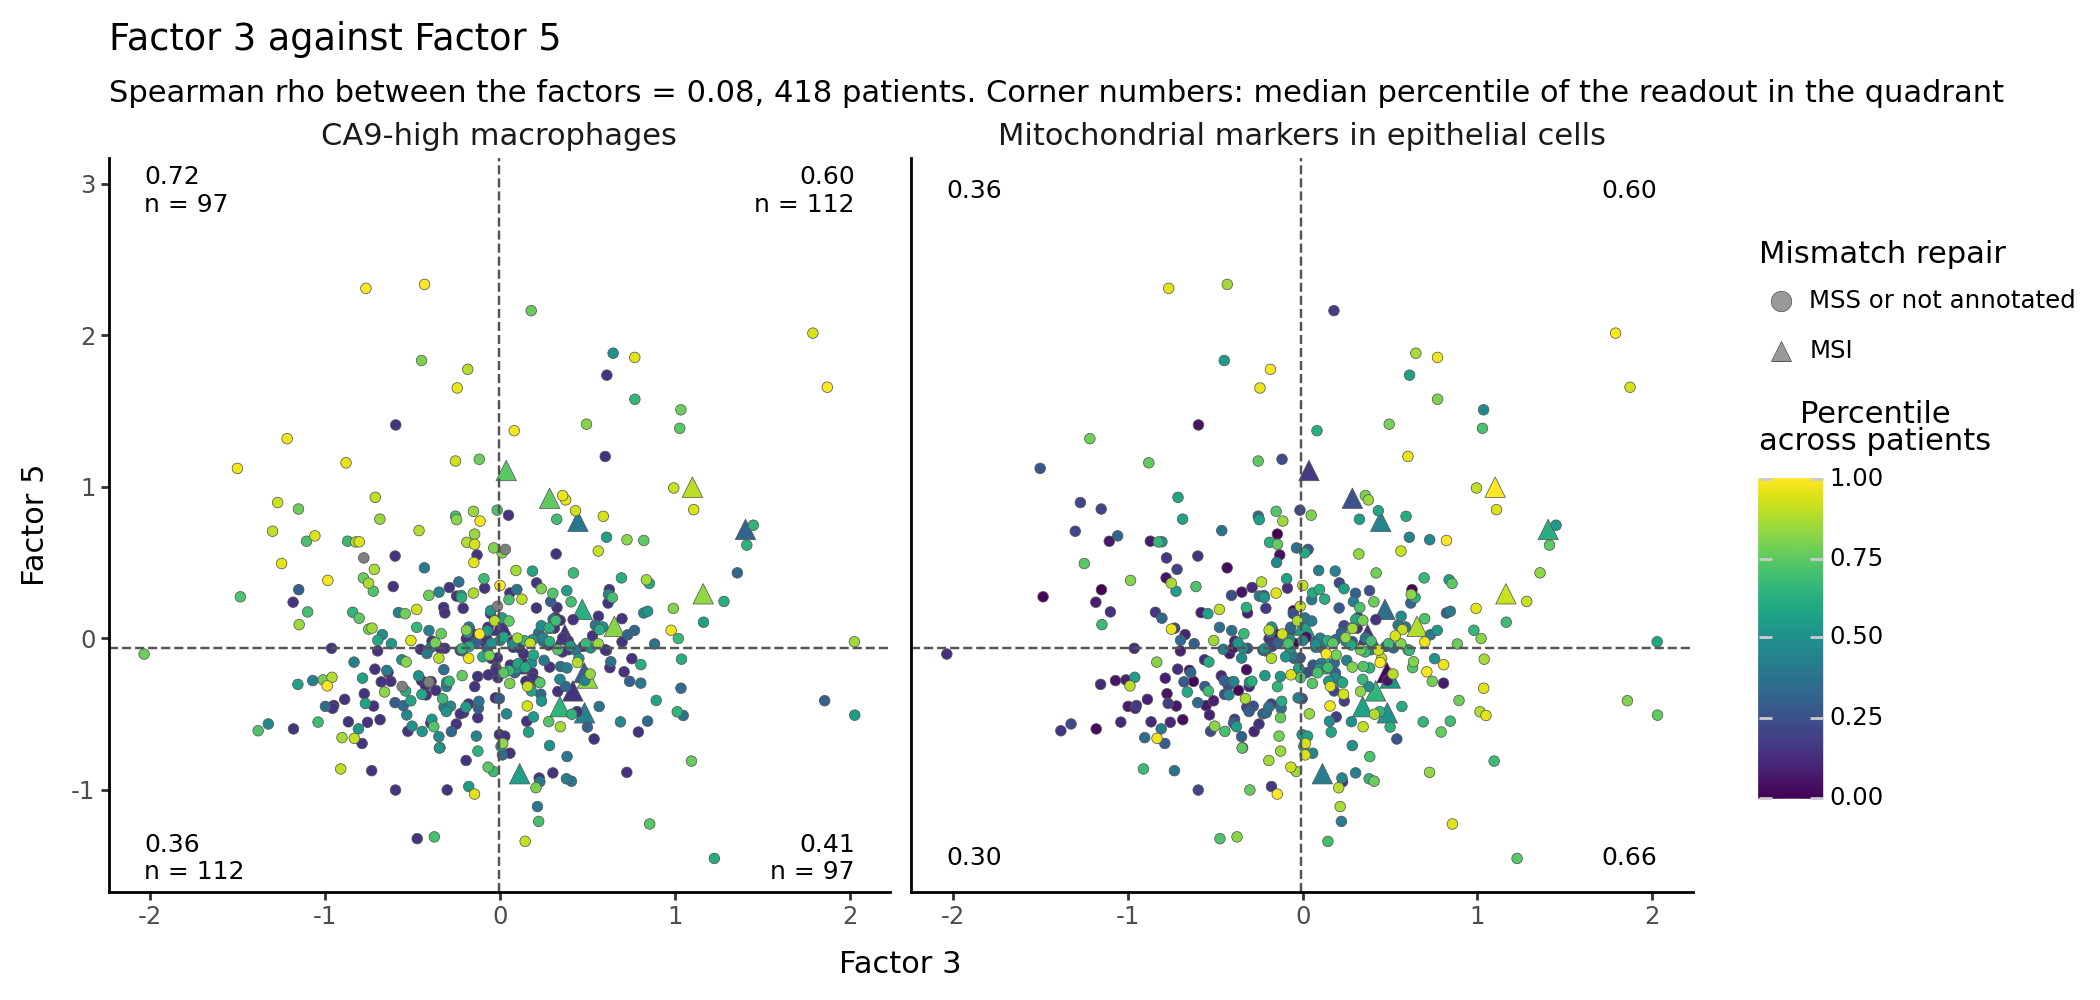

In [6]:
pair = selected
above = scores[pair] > scores[pair].quantile(factor_split_quantile)
quadrant_names = {(True, True): "F3 high, F5 high", (False, True): "F3 low, F5 high",
                  (True, False): "F3 high, F5 low", (False, False): "F3 low, F5 low"}
quadrant = pd.Series(pd.Categorical([quadrant_names[(a, b)] for a, b in above.values],
                                    categories=list(quadrant_names.values())), index=patients)

cutoffs = scores[pair].quantile(factor_split_quantile)
msi_shapes = {"MSS or not annotated": "o", "MSI": "^"}
msi_sizes = {"MSS or not annotated": 2, "MSI": 4}
points = (scores[pair].set_axis(["x", "y"], axis=1).join(percentiles)
          .assign(MSI=np.where(clinical.MSI == "MSI", "MSI", "MSS or not annotated"))
          .melt(id_vars=["x", "y", "MSI"], var_name="readout", value_name="percentile").sort_values("percentile"))
points["MSI"] = pd.Categorical(points.MSI, categories=list(msi_shapes))
corners = percentiles.groupby(quadrant, observed=True).median().rename_axis("quadrant").reset_index().melt(
    id_vars="quadrant", var_name="readout", value_name="median")
n = quadrant.value_counts()
right = corners.quadrant.str.startswith("F3 high")
corners["x"] = np.where(right, scores[pair[0]].max(), scores[pair[0]].min())
corners["y"] = np.where(corners.quadrant.str.contains("F5 high"), scores[pair[1]].max(), scores[pair[1]].min())
first = corners.readout == readouts.columns[0]
corners["label"] = [f"{m:.2f}" + (f"\nn = {n[q]}" if f else "") for m, q, f in zip(corners["median"], corners.quadrant, first)]
for df in (points, corners):
    df["readout"] = pd.Categorical(df.readout, categories=list(readouts))

gp = (ggplot(points, aes(x="x", y="y"))
      + geom_point(aes(fill="percentile", shape="MSI", size="MSI"), stroke=0.15, color="#555555")
      + geom_vline(xintercept=cutoffs[pair[0]], linetype="dashed", color="#555555")
      + geom_hline(yintercept=cutoffs[pair[1]], linetype="dashed", color="#555555")
      + scale_shape_manual(values=msi_shapes, name="Mismatch repair")
      + scale_size_manual(values=msi_sizes, guide=None)
      + geom_label(aes(label="label"), data=corners[~right], ha="left", size=9, label_size=0)
      + geom_label(aes(label="label"), data=corners[right], ha="right", size=9, label_size=0)
      + facet_wrap("~readout", ncol=2)
      + scale_fill_cmap(cmap_name="viridis", limits=(0, 1), name="Percentile\nacross patients")
      + guides(shape=guide_legend(override_aes={"fill": "#999999", "size": 4}))
      + labs(x="Factor 3", y="Factor 5", title="Factor 3 against Factor 5",
             subtitle=f"Spearman rho between the factors = {spearmanr(scores[pair[0]], scores[pair[1]])[0]:.2f}, "
                      f"{len(patients)} patients. Corner numbers: median percentile of the readout in the quadrant")
      + theme_classic()
      + theme(figure_size=(10.5, 5), strip_background=element_blank(), strip_text=element_text(size=11)))
gp.save(figure_dir + "factor3_vs_factor5.pdf", verbose=False)
gp

The CA9-high macrophages rise along Factor 5 and the mitochondrial markers along Factor 3, so each quadrant holds a different combination of the two.

In [7]:
summary = percentiles.groupby(quadrant, observed=True).median().round(2)
summary.insert(0, "patients", n[summary.index].values)
summary

,patients,CA9-high macrophages,Mitochondrial markers in epithelial cells
"F3 high, F5 high",112,0.60,0.60
"F3 low, F5 high",97,0.72,0.36
"F3 high, F5 low",97,0.41,0.66
"F3 low, F5 low",112,0.36,0.30


The pT stages and MSI status of each quadrant, as counts. `MOFACell.ipynb` found Factor 3 among the factors associated with MSI, so the MSI counts recur by construction and are not tested again here. It associated neither factor with pT.

In [8]:
pd.crosstab(quadrant, clinical.pT).join(pd.crosstab(quadrant, clinical.MSI)[["MSS", "MSI"]]).rename_axis("quadrant")

,pT1,pT2,pT3,pT4,MSS,MSI
quadrant,,,,,,
"F3 high, F5 high",5,33,56,18,88,10
"F3 low, F5 high",5,19,48,25,73,0
"F3 high, F5 low",5,18,44,30,74,7
"F3 low, F5 low",3,15,70,24,79,0


## 4. What the example could mean
The readouts measure a cell fraction and a set of proteins, not the mechanisms, so the last column gives hypotheses to test.

| Quadrant | CA9-high macrophages | Mitochondrial markers | Hypothesis for 5-FU |
|---|---|---|---|
| F3 low, F5 high | Highest of the four, 0.72 | Below the median, 0.36 | The hypoxic macrophage population of Malier et al. without the epithelial mitochondrial machinery of Moss et al. If these macrophages express dihydropyrimidine dehydrogenase, little active drug would reach epithelial cells that carry no particular survival machinery. Restoring exposure, with a dihydropyrimidine dehydrogenase inhibitor such as gimeracil or by targeting macrophages through CSF-1R, would be the step to test first |
| F3 high, F5 low | Below the median, 0.41 | Highest of the four, 0.66 | The reverse. The drug should reach the epithelial cells, but those cells carry the mitochondrial machinery that Moss et al. linked to survival. Blocking complex I would be the step to test, and these patients are the closest match to the setting of that paper |
| F3 high, F5 high | Above the median, 0.60 | Above the median, 0.60 | Both features present. The two act at different steps, so they could add up, and targeting one alone might leave the other in place |
| F3 low, F5 low | Lowest of the four, 0.36 | Lowest of the four, 0.30 | Neither feature. The fewest measured obstacles among the two mechanisms, though nothing here shows sensitivity |

The two off-diagonal quadrants carry one feature each. They are the groups where a single targeted partner would be expected to matter most, and where the two mechanisms can be told apart.

Mismatch repair adds a third feature to the picture. Cells without it tolerate 5-FU, and patients with MSI colon cancer drew no benefit from adjuvant 5-FU alone in the trials of Ribic et al. and Sargent et al. All 17 MSI tumours of the cohort fall in the two F3 high quadrants, which follows from the association between Factor 3 and MSI already reported in `MOFACell.ipynb`. What the quadrants add is that none of them lands in F3 low with F5 low, the quadrant with the lowest value of both measured readouts. That quadrant holds no tumour carrying any of the three features, which makes it the one where 5-FU would meet the fewest measured obstacles. With 17 MSI tumours and no test, this stays an observation.

## Export

In [9]:
export = readouts.join(percentiles.add_suffix(" percentile")).join(scores[pair])
export["quadrant"] = quadrant
export.rename_axis("patient").to_csv(output_dir + "readouts_per_patient.csv")
program_map.drop(columns=["readout", "factor_label", "text"]).assign(
    readout=program_map.readout.astype(str)).to_csv(output_dir + "readouts_by_program.csv", index=False)

## Appendix
### Does CA9 in a macrophage reflect its region or its neighbour?
A segmented macrophage can pick up signal from an adjacent epithelial cell. If macrophage CA9 came from such spillover, it would be high only in macrophages touching a CA9-high epithelial cell and fall to background one cell further. The plot gives the median CA9 of macrophages per patient, binned by the distance to the nearest CA9-high epithelial cell. The dashed line marks the cutoff that makes a macrophage CA9-high.

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals


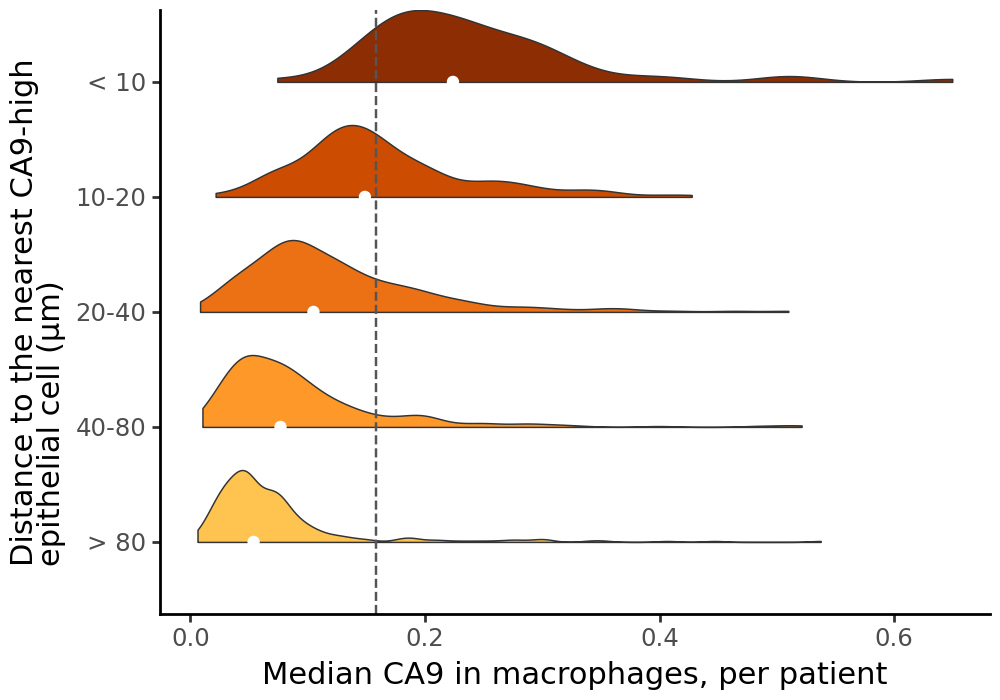

In [10]:
distances = []
for fov, fov_cells in cells.groupby("fov"):
    reference = fov_cells.loc[fov_cells.ca9_high_epithelial, ["x", "y"]].values
    if len(reference):
        m = fov_cells[fov_cells.macrophage]
        distances.append(pd.DataFrame({"fov": fov, "CA9": m.CA9.values,
                                       "distance": cKDTree(reference).query(m[["x", "y"]].values)[0] * um_per_px}))
distances = pd.concat(distances)
bin_labels = ["< 10", "10-20", "20-40", "40-80", "> 80"]
distances["bin"] = pd.cut(distances.distance, bins=[0, 10, 20, 40, 80, np.inf], labels=bin_labels, right=False)
binned = distances.groupby(["fov", "bin"], observed=True).CA9.agg(["median", "size"]).reset_index()
binned = binned[binned["size"] >= 3]
binned["bin"] = pd.Categorical(binned.bin, categories=bin_labels[::-1])

gp = (ggplot(binned, aes(x="bin", y="median"))
      + half_violins("bin")
      + geom_hline(yintercept=macrophage_ca9_cutoff, linetype="dashed", color="#555555")
      + coord_flip()
      + scale_fill_manual(values=dict(zip(bin_labels, ["#8c2d04", "#cc4c02", "#ec7014", "#fe9929", "#fec44f"])))
      + labs(x="Distance to the nearest CA9-high\nepithelial cell (µm)", y="Median CA9 in macrophages, per patient")
      + theme_classic()
      + theme(figure_size=(5, 3.5), legend_position="none"))
gp.save(figure_dir + "macrophage_ca9_by_distance.pdf", verbose=False)
gp

Two checks on the same question. The first compares macrophages that sit more than 80 µm from any CA9-high epithelial cell with the hypoxia of their own core. The second compares the cores that contain no CA9-high epithelial cell at all with the rest. Spillover cannot explain either number.

In [11]:
far = distances[distances.distance > 80].groupby("fov").CA9.median()
epithelial_ca9_fraction = epithelial_cells.CA9.gt(epithelial_ca9_cutoff).groupby(epithelial_cells.fov).mean()
hypoxic_cores = cells.groupby("fov").ca9_high_epithelial.sum() > 0
print(f"{len(far)} patients have macrophages beyond 80 µm; their median CA9 correlates with the CA9-high fraction of "
      f"their epithelial cells at rho = {spearmanr(far, epithelial_ca9_fraction[far.index])[0]:.2f}")
print(f"Macrophage CA9 median: {macrophages.CA9[macrophages.fov.map(hypoxic_cores)].median():.3f} in cores with CA9-high "
      f"epithelial cells, {macrophages.CA9[~macrophages.fov.map(hypoxic_cores)].median():.3f} in the "
      f"{(~hypoxic_cores).sum()} cores without any")

283 patients have macrophages beyond 80 µm; their median CA9 correlates with the CA9-high fraction of their epithelial cells at rho = 0.61
Macrophage CA9 median: 0.089 in cores with CA9-high epithelial cells, 0.030 in the 33 cores without any


### Which cell types express the markers
Each half violin shows the distribution, across patients, of the median of a marker in one cell type. It shows how much lower CA9 is in macrophages than in epithelial cells, which is why the CA9-high cutoff is taken within each population.

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x interval

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x interval

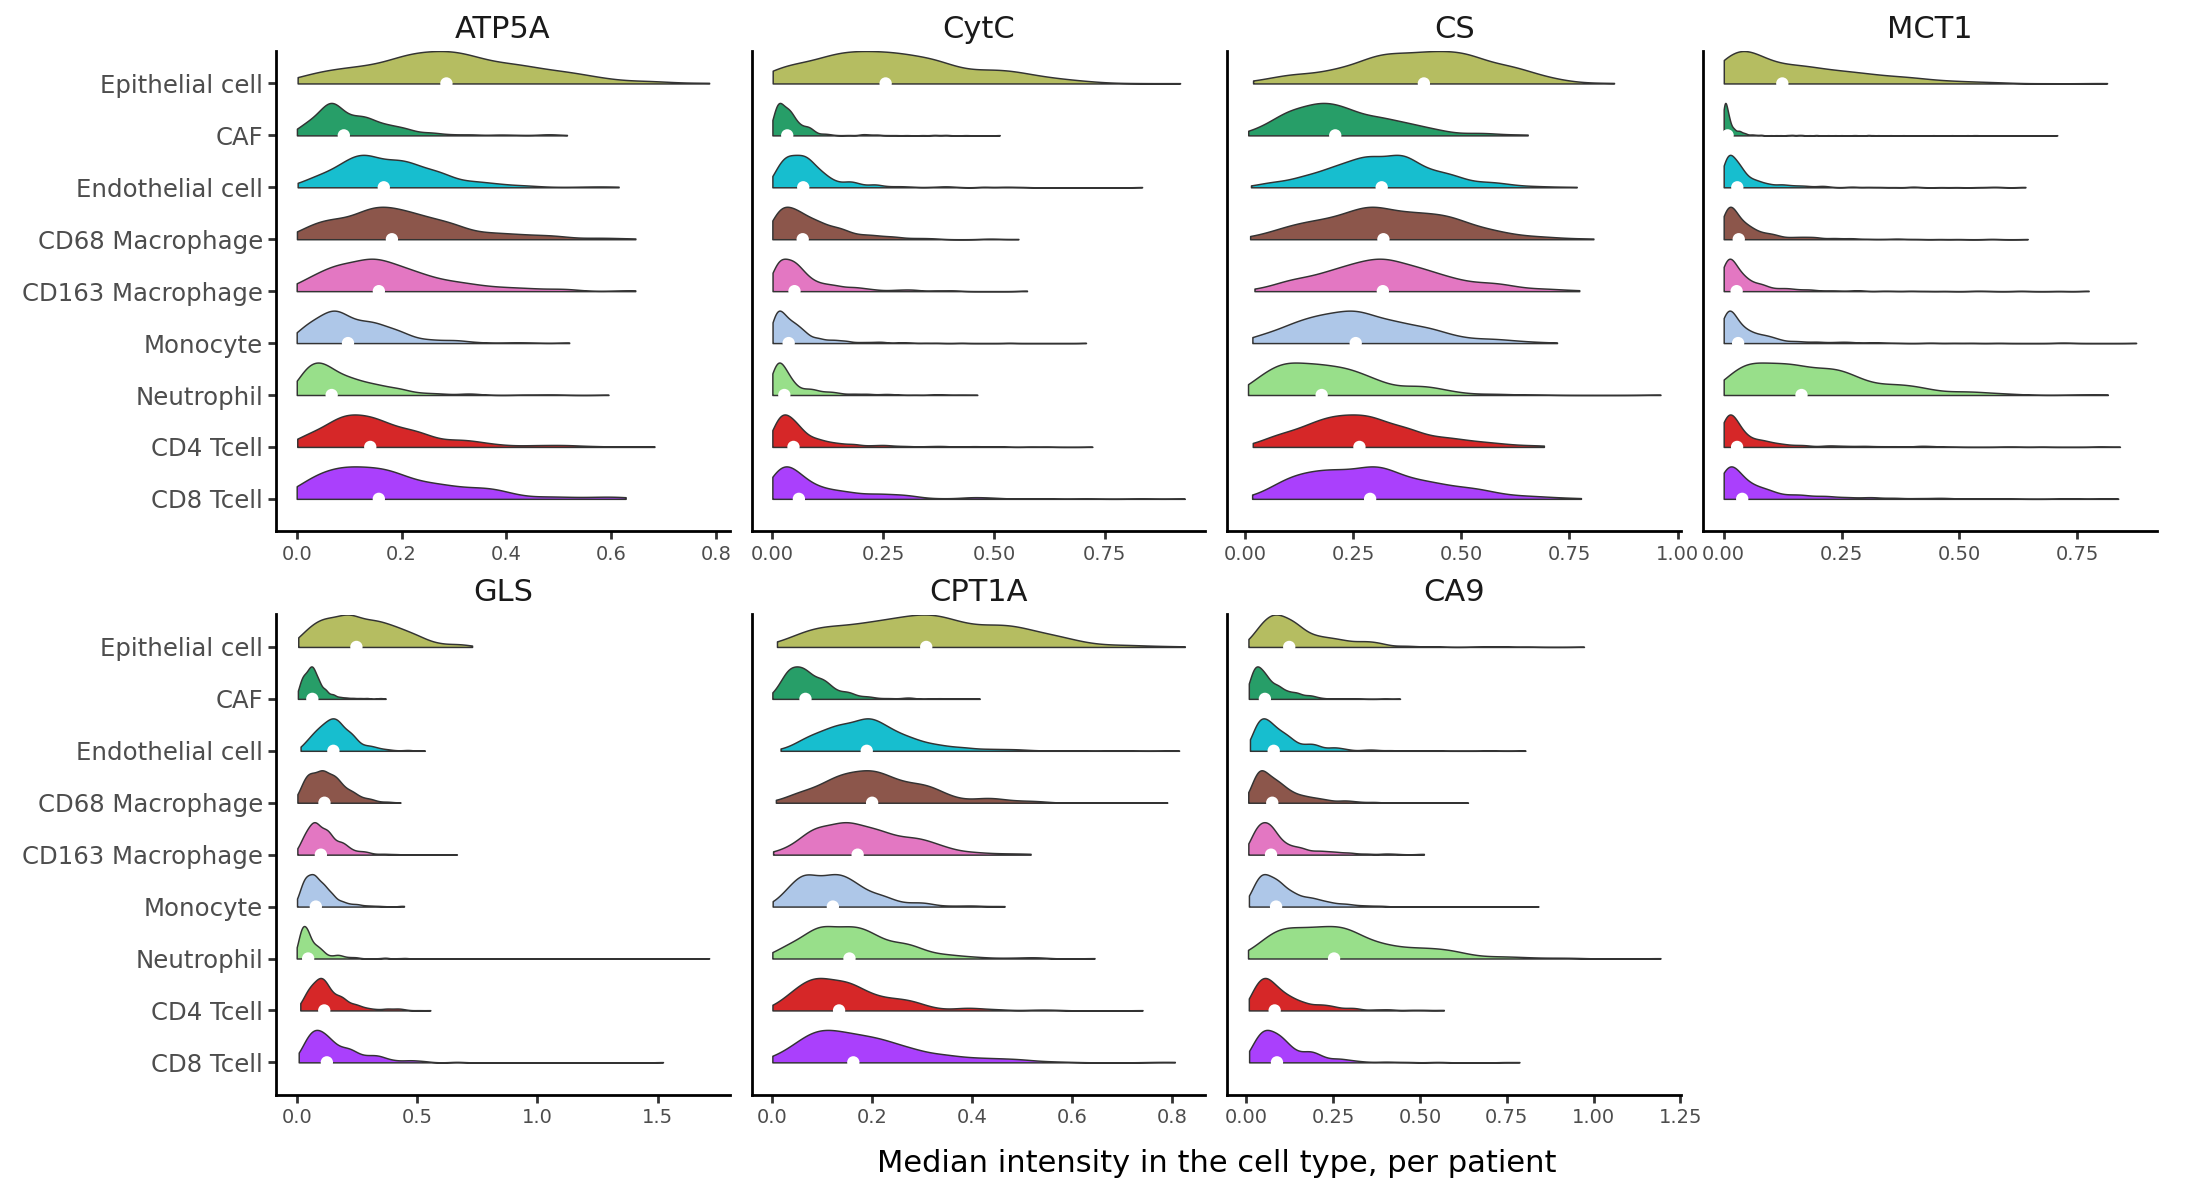

In [12]:
type_colors = dict(zip(ad.read_h5ad(data_dir + "adata_consensus_cell_types.h5ad", backed="r").obs["annotation_consensus"].cat.categories,
                       default_20))
qc_types = ["Cancer_cell", "CAF", "Endothelial_cell", "CD68_Macrophage", "CD163_Macrophage", "Monocyte",
            "Neutrophil", "CD4_Tcell", "CD8_Tcell"]
type_names = {t: "Epithelial cell" if t == epithelial_label else t.replace("_", " ") for t in qc_types}
type_medians = (cells[cells.cell_type.isin(qc_types)].groupby(["fov", "cell_type"])[marker_columns].median().reset_index()
                .melt(id_vars=["fov", "cell_type"], var_name="marker", value_name="median"))
type_medians["marker"] = pd.Categorical(type_medians.marker, categories=marker_columns)
type_medians["cell_type"] = pd.Categorical(type_medians.cell_type.map(type_names),
                                           categories=[type_names[t] for t in qc_types][::-1])
gp = (ggplot(type_medians, aes(x="cell_type", y="median"))
      + half_violins("cell_type")
      + coord_flip()
      + facet_wrap("~marker", scales="free_x", ncol=4)
      + scale_fill_manual(values={type_names[t]: type_colors[t] for t in qc_types})
      + labs(x="", y="Median intensity in the cell type, per patient")
      + theme_classic()
      + theme(figure_size=(11, 6), legend_position="none", axis_text_x=element_text(size=7),
              strip_background=element_blank(), strip_text=element_text(size=11)))
gp.save(figure_dir + "marker_medians_per_cell_type.pdf", verbose=False)
gp

### Do the mitochondrial markers reflect the epithelial cells?
The markers could also follow the staining intensity of a core, which all its cells share. The same score computed on the epithelial median minus the median of all other annotated cells removes that shared part. A high correlation between the two means that most of the variation between patients comes from the epithelial cells.

In [13]:
other = cells[~cells.epithelial & (cells.cell_type != "Unclear")].groupby("fov")[mitochondrial_markers].median().loc[patients]
contrast = epithelial_cells.groupby("fov")[mitochondrial_markers].median().loc[patients] - other
contrast_score = pd.concat([zscore(contrast[m]) for m in mitochondrial_markers], axis=1).mean(axis=1)
print("Spearman rho between the mitochondrial markers and the same score on the epithelial contrast: %.2f"
      % spearmanr(readouts["Mitochondrial markers in epithelial cells"], contrast_score, nan_policy="omit")[0])

Spearman rho between the mitochondrial markers and the same score on the epithelial contrast: 0.77
